# Black-Litterman Portfolio with LSTM + SVR Investor's Views

**Architecture B** — one multi-output LSTM per stock (predicts all 8 indicators at once),
then an SVR decodes the predicted indicators into a price forecast. The forecast becomes
the Black-Litterman view (Q), and the model's error sets the view's uncertainty (Ω).

```
yfinance OHLCV → 8 indicators → 30-day windows
   → LSTM (1 per stock, 8 outputs) → SVR (indicators → price)
   → views Q + Ω → Black-Litterman w*  → backtest vs SPY
```

This notebook **reuses the verified `bl_lstm_views/src` modules** (so the heavy logic is
tested), and keeps the project's two refinements over the raw design doc:

- **Stationary price target** — the SVR predicts `close / SMA₃₀(close) − 1`, not the raw
  price level, so an RBF model can't be wrecked by the 2010→2025 price trend.
- **Long-only + capped, renormalised weights** and the **no-views ⇒ w\*=w_mkt** identity.

> Research scaffold, **not** a profitable strategy — backtest numbers are illustrative.
> See `README.md` for the full caveats.

In [60]:
# Fresh setup:  pip install -r requirements.txt   (numpy pandas scikit-learn yfinance torch)
import os, sys, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, os.getcwd())          # run this notebook from the bl_lstm_views/ folder
from src import constants as C
from src import fetch_data, black_litterman as bl
from src.indicators import add_indicators
from src.preprocessing import build_stock_dataset
from src.lstm_model import LSTMRegressor, get_device, train_stock_model, predict_indicators
from src.svr_model import train_close_svr, predict_price, train_fit_mse
from src.views import compose_view, assemble_package, write_views_json
from src.backtest import run_backtest

TICKERS    = ["RKLB","AMAT", "CRWD", "IONQ", "LLY", "EOSE", "ASML", "ELV", "PLTR", "OKLO"]
EPOCHS     = int(os.environ.get("BL_EPOCHS", 400))      # fast demo; paper uses C.PAPER_EPOCHS (400)
MAX_WEIGHT = 0.40                                       # per-asset cap (feasible for 5 names)
device     = get_device(os.environ.get("BL_DEVICE", "auto"))

pct = lambda x: np.round(np.asarray(x, float) * 100, 2)  # decimals → %
print("torch", torch.__version__, "| device:", device.type)
print("tickers:", TICKERS, "| epochs:", EPOCHS)

torch 2.12.1 | device: mps
tickers: ['RKLB', 'AMAT', 'CRWD', 'IONQ', 'LLY', 'EOSE', 'ASML', 'ELV', 'PLTR', 'OKLO'] | epochs: 400


## Step 1 — Fetch Data
Daily OHLCV + market caps from yfinance (cached to `output/cache/`).

In [61]:
data   = fetch_data.fetch(TICKERS)
prices = data["prices"]
caps   = data["market_caps"]
bench  = fetch_data.download_prices(C.BENCHMARK, C.DATA_START, C.DATA_END)
bench_close = bench["close"] if bench is not None else None

pd.DataFrame({t: {"days": len(df), "mkt_cap_$B": round(caps.get(t, 0) / 1e9, 1)}
              for t, df in prices.items()}).T

  ↗  Fetching ['RKLB', 'AMAT', 'CRWD', 'IONQ', 'LLY', 'EOSE', 'ASML', 'ELV', 'PLTR', 'OKLO']  (2010-01-01 → 2026-01-01)
  ✅  RKLB: 1281 daily bars
  ✅  AMAT: 4024 daily bars
  ✅  CRWD: 1649 daily bars
  ✅  IONQ: 1255 daily bars
  ✅  LLY: 4024 daily bars
  ✅  EOSE: 1297 daily bars
  ✅  ASML: 4024 daily bars
  ✅  ELV: 4024 daily bars
  ✅  PLTR: 1320 daily bars
  ✅  OKLO: 1127 daily bars
  ✅  SPY: 4024 daily bars


,days,mkt_cap_$B
RKLB,1281.0,55.7
AMAT,4024.0,465.8
CRWD,1649.0,173.0
IONQ,1255.0,20.2
LLY,4024.0,986.7
EOSE,1297.0,2.1
ASML,4024.0,678.1
ELV,4024.0,84.1
PLTR,1320.0,277.3
OKLO,1127.0,9.5


## Step 2 — Compute Indicators (8)
MACD · RSI · squeeze_on · BB_width · KC_width · sq_momentum · OBV · Hilbert — all pure pandas/numpy (`src/indicators.py`).

In [62]:
sample = add_indicators(prices[TICKERS[0]])[C.FEATURES].dropna()
print(f"{TICKERS[0]}: {sample.shape[0]} rows x {sample.shape[1]} features")
sample.tail()

RKLB: 1251 rows x 8 features


Price,macd,rsi,squeeze_on,bb_width,kc_width,sq_momentum,obv,hilbert
Date,,,,,,,,
2025-12-24,6.383154,74.044224,0,46.987071,16.506834,16.151566,1.335500e+09,30.0
2025-12-26,6.361102,63.441953,0,46.673440,16.874755,15.197121,1.312342e+09,30.0
2025-12-29,6.229055,62.657749,0,45.597923,16.244207,14.334520,1.294048e+09,30.0
2025-12-30,6.080937,62.964711,0,43.220051,16.002854,14.085564,1.324199e+09,30.0
2025-12-31,5.840550,61.820411,0,40.330086,15.640487,13.146789,1.306605e+09,30.0


## Step 3 — Preprocess
Train-only MinMax scaling, 30-day windows, 5-day-ahead targets (`src/preprocessing.py`). Split: train ≤2023 · val 2024 · test 2025.

In [63]:
stock_data = {t: build_stock_dataset(t, prices[t]) for t in TICKERS if t in prices}
sd0 = stock_data[TICKERS[0]]; w = sd0.windows
print("X:", w["X"].shape, " Y:", w["Y"].shape,
      " (window=", C.TIME_WINDOW, ", features=", C.LSTM_OUTPUTS, ", horizon=", C.HORIZON, ")")
print("windows  train/val/test:", int(w["train"].sum()), int(w["val"].sum()), int(w["test"].sum()))

X: (1217, 30, 8)  Y: (1217, 8)  (window= 30 , features= 8 , horizon= 5 )
windows  train/val/test: 720 252 245


## Step 4 — Train LSTM (Architecture B)
One 4-layer LSTM per stock, `Dense(60 → 8)` multi-output head. Adam(5e-3), dropout 0.30, val-driven early stopping + LR plateau.

In [64]:
demo = LSTMRegressor()
print(demo)
print(f"\n{sum(p.numel() for p in demo.parameters()):,} params per stock"
      f"  ->  {len(stock_data)} models total (Architecture B)")

LSTMRegressor(
  (lstm): LSTM(8, 60, num_layers=4, batch_first=True, dropout=0.3)
  (head): Linear(in_features=60, out_features=8, bias=True)
)

105,128 params per stock  ->  10 models total (Architecture B)


In [65]:
lstm_results = {}
for t, sd in stock_data.items():
    print(f"\nTraining {t} ...")
    lstm_results[t] = train_stock_model(sd, epochs=EPOCHS, device=device)
print("\nLSTM training done.")

pd.DataFrame({t: {"val_MSE": round(r["val_mse"], 4),
                  "test_MSE_mean": round(float(np.nanmean(r["mse_test"])), 4)}
              for t, r in lstm_results.items()}).T


Training RKLB ...
      [RKLB] early stop at epoch 52 (best val 0.1961)

Training AMAT ...
      [AMAT] early stop at epoch 56 (best val 0.1315)

Training CRWD ...
      [CRWD] early stop at epoch 43 (best val 0.1204)

Training IONQ ...
      [IONQ] early stop at epoch 66 (best val 0.1049)

Training LLY ...
      [LLY] early stop at epoch 58 (best val 0.1564)

Training EOSE ...
      [EOSE] early stop at epoch 83 (best val 0.0596)

Training ASML ...
      [ASML] epoch 100 | train 0.0058 | val 0.0951
      [ASML] early stop at epoch 100 (best val 0.0852)

Training ELV ...
      [ELV] early stop at epoch 63 (best val 0.0482)

Training PLTR ...
      [PLTR] early stop at epoch 74 (best val 0.1433)

Training OKLO ...
      [OKLO] early stop at epoch 49 (best val 55.6485)

LSTM training done.


,val_MSE,test_MSE_mean
RKLB,0.1961,2.5672
AMAT,0.1315,0.1615
CRWD,0.1204,0.1524
IONQ,0.1049,0.5699
LLY,0.1564,0.2404
EOSE,0.0596,0.0584
ASML,0.0852,0.0714
ELV,0.0482,0.0488
PLTR,0.1433,0.9866
OKLO,55.6485,1901.0170


## Step 5 — Train SVR
SVR(RBF, C=5, ε=0.01) maps scaled indicators → `close/SMA₃₀ − 1` (the stationary target). At inference it decodes the LSTM's forecast into a price.

In [66]:
svr_models = {t: train_close_svr(sd) for t, sd in stock_data.items()}
pd.DataFrame({t: {"SVR_fit_MSE": round(train_fit_mse(svr_models[t], stock_data[t]), 5)}
              for t in stock_data}).T

,SVR_fit_MSE
RKLB,0.00025
AMAT,0.00015
CRWD,0.00027
IONQ,0.00076
LLY,0.00007
EOSE,0.00183
ASML,0.00014
ELV,0.00009
PLTR,0.00042
OKLO,0.00002


## Step 6 — Black-Litterman
Compose each stock's view (`compose_view`), build Π, μ_BL and the optimal weights w\* (`src/black_litterman.py`), and export `views.json`.

In [67]:
per_stock = {t: compose_view(stock_data[t], lstm_results[t], svr_models[t]) for t in stock_data}
views     = assemble_package(per_stock)
tickers   = views["tickers"]

panel = pd.DataFrame({t: pd.Series(stock_data[t].close_raw,
                      index=pd.DatetimeIndex(stock_data[t].dates).normalize())
                      for t in tickers}).dropna()
sigma = bl.covariance(panel.pct_change().dropna().to_numpy())
w_mkt = bl.market_weights(np.array([caps.get(t, 0) for t in tickers]))
res   = bl.solve(sigma, w_mkt, P=views["P"], Q=views["Q"], omega=views["omega"], max_weight=MAX_WEIGHT)

write_views_json(views)
print("views.json ->", os.path.relpath(C.VIEWS_JSON))

pd.DataFrame({
    "view_q_5d_%": pct([per_stock[t]["q_horizon"] for t in tickers]),
    "Pi_ann_%":    pct(res["pi"]),
    "muBL_ann_%":  pct(res["mu_bl"]),
    "w_mkt_%":     pct(w_mkt),
    "w_star_%":    pct(res["w_star"]),
    "dW_%":        pct(res["w_star"] - w_mkt),
}, index=tickers)

views.json -> output/views.json


,view_q_5d_%,Pi_ann_%,muBL_ann_%,w_mkt_%,w_star_%,dW_%
RKLB,-22.60,24.69,24.28,2.02,1.83,-0.20
AMAT,-1.38,25.33,25.18,16.92,16.89,-0.03
CRWD,3.04,22.81,22.70,6.29,6.40,0.11
IONQ,-8.73,35.06,34.66,0.73,0.67,-0.06
LLY,4.87,13.36,13.41,35.85,36.28,0.43
EOSE,4.50,25.88,25.71,0.08,0.10,0.02
ASML,-1.48,25.37,25.21,24.63,24.54,-0.10
ELV,-2.79,4.12,4.08,3.05,2.86,-0.19
PLTR,-8.19,31.49,31.21,10.08,9.99,-0.09
OKLO,23.38,12.12,12.15,0.35,0.45,0.11


## Step 7 — Evaluate
Rolling 5-day-rebalance backtest vs SPY (annual return, Sharpe, max drawdown), plus the weight tilt the views produced.

backtest grid 2025-01-02 -> 2025-12-17  (48 rebalances)


,ann_return,ann_vol,sharpe,max_drawdown
BL+model,0.6603,0.2955,2.0652,-0.2120
SPY_buy_hold,0.1670,0.1935,0.6046,-0.1856


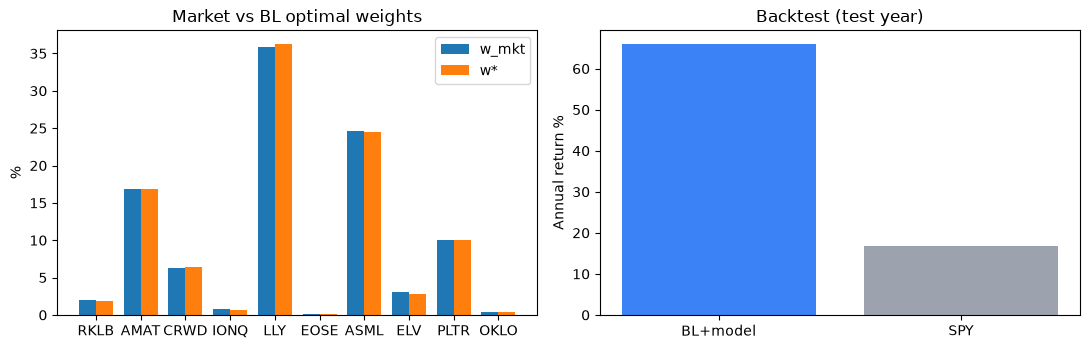

In [68]:
bt = run_backtest(stock_data, views, w_mkt, bench_close, max_weight=MAX_WEIGHT)
s, b = bt["strategy"], bt["benchmark"]
print(f"backtest grid {bt['grid_start']} -> {bt['grid_end']}  ({bt['n_rebalances']} rebalances)")

metrics = pd.DataFrame(
    {"BL+model": s, "SPY_buy_hold": b}).T[["ann_return", "ann_vol", "sharpe", "max_drawdown"]]
display(metrics.round(4))

import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
x, bw = np.arange(len(tickers)), 0.38
ax[0].bar(x - bw/2, pct(w_mkt), bw, label="w_mkt")
ax[0].bar(x + bw/2, pct(res["w_star"]), bw, label="w*")
ax[0].set_xticks(x); ax[0].set_xticklabels(tickers); ax[0].set_ylabel("%")
ax[0].set_title("Market vs BL optimal weights"); ax[0].legend()
ax[1].bar(["BL+model", "SPY"], [s["ann_return"]*100, b["ann_return"]*100], color=["#3b82f6", "#9ca3af"])
ax[1].set_ylabel("Annual return %"); ax[1].set_title("Backtest (test year)")
plt.tight_layout(); plt.show()